# Chapitre 10 - Cours 2 : Routeur, passerelle, caches et motifs agentiques

Nous poursuivons la construction de l'architecture commencée au cours 1 (contexte et
garde-fous). L'application ÉlectroNova va maintenant apprendre à **orienter** les requêtes
(routeur d'intention), à **parler à plusieurs modèles** de façon sûre et résiliente
(passerelle), à **ne pas recalculer** ce qu'elle sait déjà (caches), à **boucler** quand une
première réponse ne suffit pas et enfin à **agir** (actions d'écriture).

Sections du livre couvertes : *Step 3. Add Model Router and Gateway* (*Router*, *Gateway*),
*Step 4. Reduce Latency with Caches* (*Exact caching*, *Semantic caching*),
*Step 5. Add Agent Patterns*.

Plan :
1. étape 3a : le routeur d'intention ;
2. étape 3b : la passerelle de modèles ;
3. étape 4a : le cache exact ;
4. étape 4b : le cache sémantique ;
5. étape 5 : les motifs agentiques ;
6. étape 6 : les actions d'écriture.

In [1]:
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix
from aie.plotting import set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, COLORS, annotate_bars
from aie.diagrams import Diagram
from aie import llm
from aie import ch10_architecture as A

set_style()
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
qwen = lambda messages: llm.chat(messages, model_id=llm.SMALL, max_new_tokens=80)
embed = lambda texts: llm.embed(texts, llm.EMBED_MULTI)      # MiniLM multilingue
embed_en = lambda texts: llm.embed(texts, llm.EMBED)         # MiniLM entraîné sur l'anglais

## 1. Étape 3a : le routeur d'intention (section *Router*)

**Le problème.** Utiliser un seul modèle pour toutes les requêtes est rarement optimal.
Certaines demandes ont une réponse toute faite (réinitialiser un mot de passe), d'autres
doivent aller à un humain (litige de facturation), d'autres à un modèle spécialisé
(dépannage technique), et certaines sont hors périmètre (« pour qui vas-tu voter ? »). Un
**routeur** prédit l'intention de l'utilisateur et envoie la requête à la bonne solution.
Deux bénéfices : la **spécialisation** (meilleure qualité) et les **économies** (les
requêtes simples vont vers des solutions bon marché).

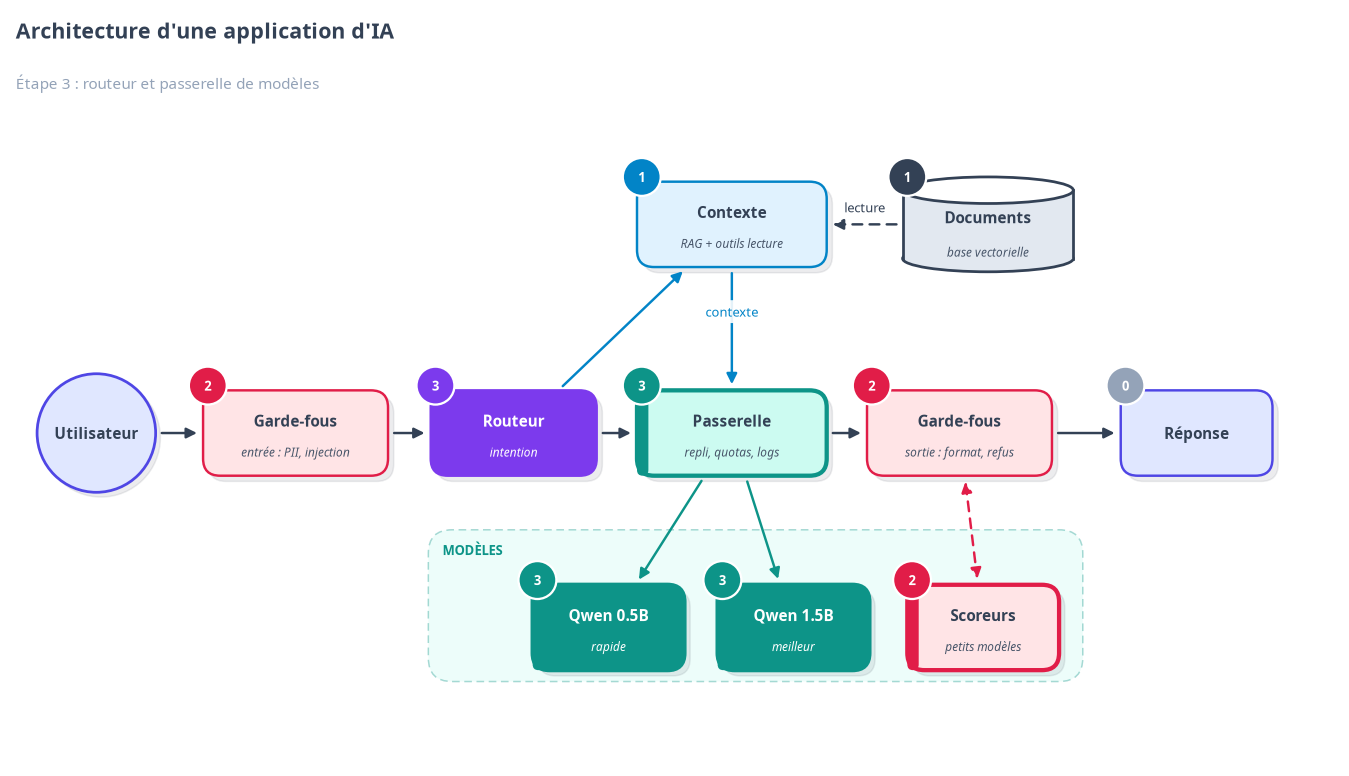

In [2]:
A.architecture_diagram(3);

Notre routeur est un classifieur d'intention sur 5 classes, entraîné sur 10 exemples
rédigés à la main par classe (`A.INTENTS_TRAIN`), et testé sur 20 phrases différentes
(`A.INTENTS_TEST`). Le tableau rappelle où part chaque intention.

In [3]:
pd.DataFrame([{"intention": k, "exemple": v[0], "destination": A.ROUTES[k]} for k, v in A.INTENTS_TRAIN.items()])

,intention,exemple,destination
0,mot_de_passe,J'ai oublié mon mot de passe,page FAQ
1,facturation,J'ai été débité deux fois,opérateur humain
2,technique,Mon casque Bluetooth ne s'appaire pas,chatbot dépannage (LLM + RAG)
3,commande,Où en est ma commande ?,agent commandes (outils)
4,hors_perimetre,Pour qui vas-tu voter aux prochaines élections ?,réponse type polie


**Le classifieur.** On encode chaque phrase avec un modèle d'embeddings (MiniLM) puis on
compare la requête à chaque intention. Deux variantes :
- **centroïde** : on moyenne les embeddings des exemples de chaque intention $c$,
  $\mu_c = \frac{1}{n_c}\sum_{i : y_i = c} e_i$, et on prédit
  $\hat y = \arg\max_c \cos(e_q, \mu_c)$ ;
- **$k$ plus proches voisins** : le score d'une intention est la similarité moyenne des
  $k$ exemples de cette intention les plus proches de la requête.

Aucun entraînement de réseau : il suffit d'un modèle d'embeddings et de quelques exemples
par classe. C'est ce qui rend le routeur **rapide et bon marché**, une exigence du livre
puisqu'on peut enchaîner plusieurs routeurs. Visualisons les embeddings projetés en 2D.

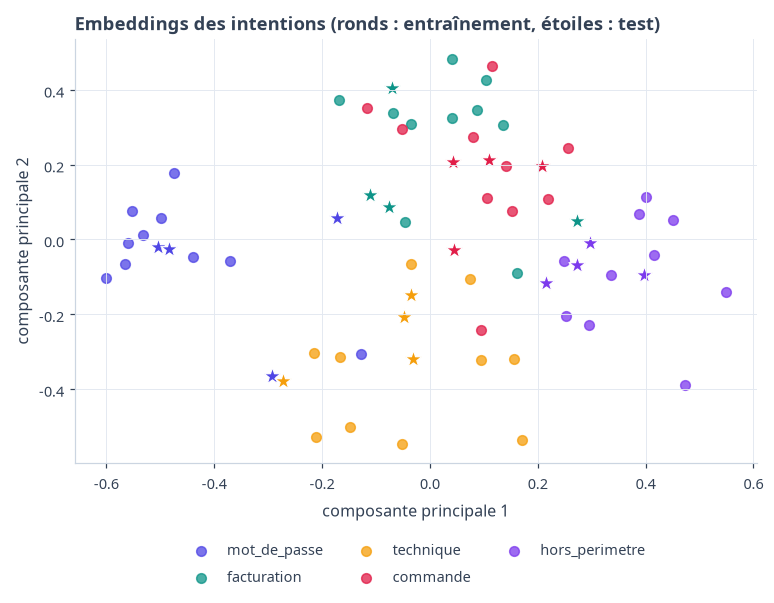

In [4]:
labels = list(A.INTENTS_TRAIN)
train_txt = [t for l in labels for t in A.INTENTS_TRAIN[l]]
train_y = [l for l in labels for _ in A.INTENTS_TRAIN[l]]
test_txt = [t for t, _ in A.INTENTS_TEST]; test_y = [l for _, l in A.INTENTS_TEST]
E_tr, E_te = embed(train_txt), embed(test_txt)
pca = PCA(2, random_state=0).fit(E_tr)
P_tr, P_te = pca.transform(E_tr), pca.transform(E_te)
fig, ax = plt.subplots(figsize=(8, 5))
for l, c in zip(labels, COLORS):
    m = np.array(train_y) == l
    ax.scatter(*P_tr[m].T, color=c, s=40, alpha=0.75, label=l)
    mt = np.array(test_y) == l
    ax.scatter(*P_te[mt].T, color=c, s=140, marker="*", edgecolor="white", linewidth=0.8)
ax.set(xlabel="composante principale 1", ylabel="composante principale 2",
       title="Embeddings des intentions (ronds : entraînement, étoiles : test)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.show()

Les intentions forment des nuages assez séparés, même en 2 dimensions (sur 384). Comparons
trois encodeurs : le MiniLM **multilingue**, le MiniLM **anglais** (`all-MiniLM-L6-v2`) et
notre embedding lexical `hash_embed` (sac de trigrammes de caractères, sans aucune
sémantique).

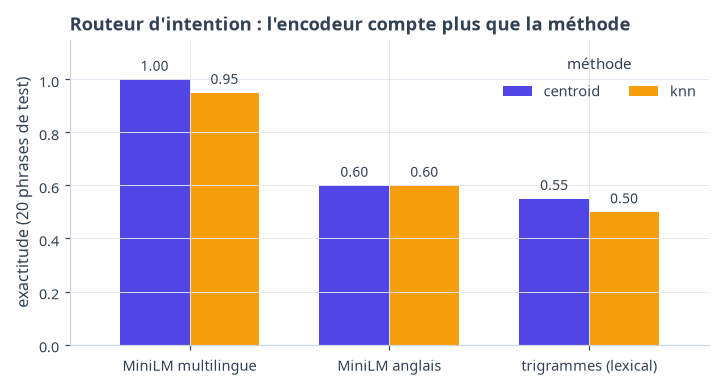

In [5]:
encodeurs = {"MiniLM multilingue": embed, "MiniLM anglais": embed_en, "trigrammes (lexical)": A.hash_embed}
rows, routers = [], {}
for name, f in encodeurs.items():
    for method in ["centroid", "knn"]:
        r = A.IntentRouter(f, method=method, k=3).fit(A.INTENTS_TRAIN)
        routers[(name, method)] = r
        acc = np.mean(np.array(r.predict(test_txt)) == np.array(test_y))
        rows.append({"encodeur": name, "méthode": method, "exactitude": acc})
acc = pd.DataFrame(rows).pivot(index="encodeur", columns="méthode", values="exactitude").loc[list(encodeurs)]
ax = acc.plot.bar(color=[INDIGO, AMBER], figsize=(7.5, 3.6), rot=0, width=0.7)
annotate_bars(ax, "{:.2f}")
ax.set(ylabel="exactitude (20 phrases de test)", xlabel="", ylim=(0, 1.15),
       title="Routeur d'intention : l'encodeur compte plus que la méthode")
ax.legend(title="méthode", ncol=2); plt.show()

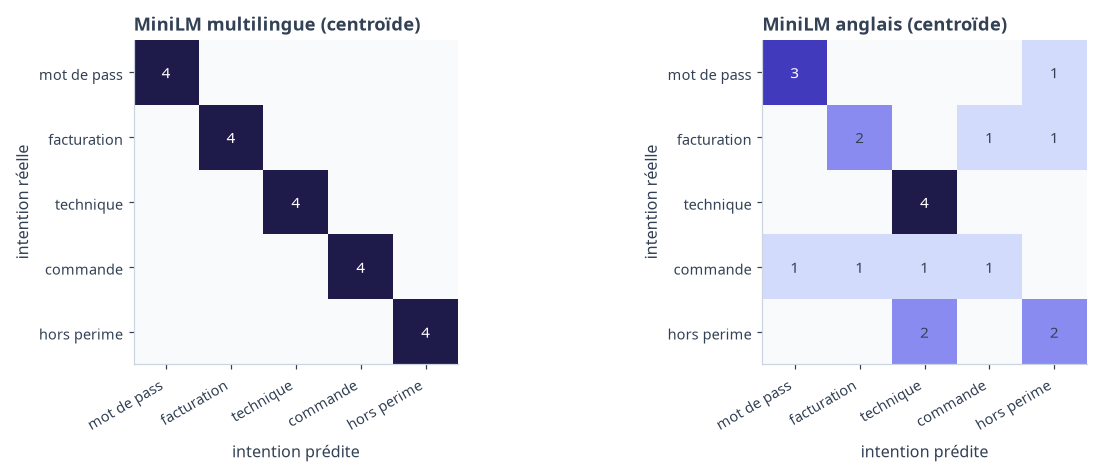

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, name in zip(axes, ["MiniLM multilingue", "MiniLM anglais"]):
    pred = routers[(name, "centroid")].predict(test_txt)
    cm = confusion_matrix(test_y, pred, labels=labels)
    ax.imshow(cm, cmap="aie_seq"); ax.grid(False)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 2 else SLATE)
    short = [l.replace("_", " ")[:11] for l in labels]
    ax.set_xticks(range(5), short, rotation=30, ha="right"); ax.set_yticks(range(5), short)
    ax.set(xlabel="intention prédite", ylabel="intention réelle", title=f"{name} (centroïde)")
plt.tight_layout(); plt.show()

Le MiniLM multilingue est presque parfait ; le MiniLM anglais, qui a vu peu de français,
confond de nombreuses classes, à peine mieux que les trigrammes. Leçon : un routeur
n'est jamais meilleur que la représentation sur laquelle il repose, et celle-ci doit
correspondre à la langue et au domaine des utilisateurs.

**Requêtes ambiguës et hors périmètre.** Le livre donne l'exemple de « Freezing » : geler
son compte ou parler de la météo ? Un routeur doit pouvoir dire « je ne sais pas » et
demander une clarification. Règle simple : si le meilleur score est trop faible, ou trop
proche du second (marge $s_{(1)} - s_{(2)} < \delta$), on renvoie « ambigu ».

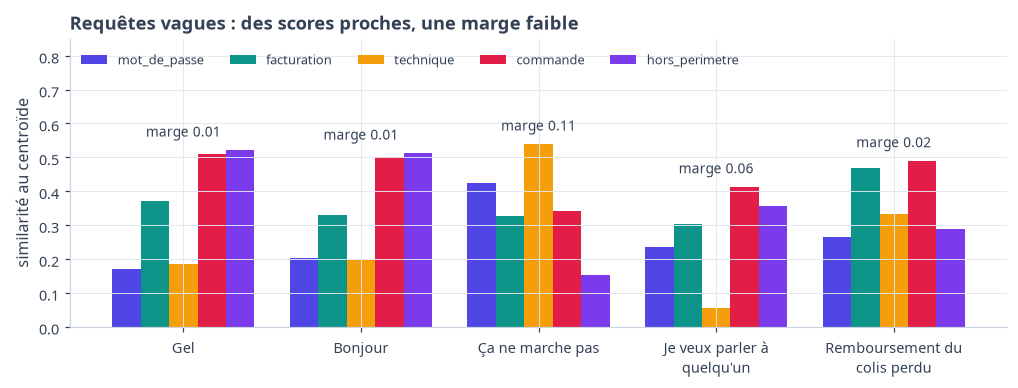

In [7]:
router = routers[("MiniLM multilingue", "centroid")]
vagues = ["Gel", "Bonjour", "Ça ne marche pas", "Je veux parler à quelqu'un", "Remboursement du colis perdu"]
S = router.scores(vagues)
fig, ax = plt.subplots(figsize=(11, 3.4))
w = 0.16
for j, (l, c) in enumerate(zip(labels, COLORS)):
    ax.bar(np.arange(len(vagues)) + (j - 2) * w, S[:, j], w, color=c, label=l)
srt = np.sort(S, axis=1)
for i in range(len(vagues)):
    ax.text(i, S[i].max() + 0.04, f"marge {srt[i, -1] - srt[i, -2]:.2f}", ha="center", fontsize=9)
ax.set_xticks(range(len(vagues)), [textwrap.fill(v, 16) for v in vagues]); ax.set_ylabel("similarité au centroïde"); ax.set_ylim(0, 0.85)
ax.set_title("Requêtes vagues : des scores proches, une marge faible"); ax.legend(ncol=5, fontsize=8.5, loc="upper left")
plt.show()

In [8]:
strict = A.IntentRouter(embed, threshold=0.3, margin=0.05).fit(A.INTENTS_TRAIN)
pd.DataFrame({"requête": vagues + test_txt[:3],
              "sans règle de rejet": router.predict(vagues + test_txt[:3]),
              "seuil 0,30 et marge 0,05": strict.predict(vagues + test_txt[:3])})

,requête,sans règle de rejet,"seuil 0,30 et marge 0,05"
0,Gel,hors_perimetre,ambigu
1,Bonjour,hors_perimetre,ambigu
2,Ça ne marche pas,technique,technique
3,Je veux parler à quelqu'un,commande,commande
4,Remboursement du colis perdu,commande,ambigu
5,Je ne me souviens plus de mes identifiants,mot_de_passe,mot_de_passe
6,Le code de connexion est refusé à chaque fois,mot_de_passe,ambigu
7,Comment modifier mon mot de passe sur l'application ?,mot_de_passe,mot_de_passe


La règle de marge renvoie les requêtes vagues vers une demande de clarification et laisse
passer la plupart des requêtes nettes ; elle peut aussi « sur-clarifier » une requête
légitime (relisez la colonne de droite). Les seuils se règlent sur des données annotées
(exercice 10.4) : trop stricts, ils agacent l'utilisateur avec des questions inutiles.

**Combien le routeur fait-il économiser ?** Supposons qu'un appel au grand modèle coûte
$c_G$, une réponse type ou une page FAQ $\approx 0$, et qu'une fraction $f_{FAQ}$ du
trafic soit résolue sans LLM et une fraction $f_P$ envoyée à un petit modèle de coût
$c_P = c_G/10$. Le coût moyen par requête devient
$$c = c_{routeur} + f_P\,c_P + (1 - f_{FAQ} - f_P)\,c_G .$$

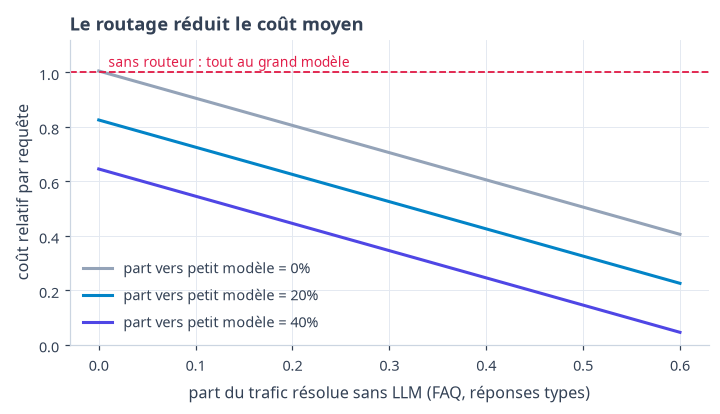

In [9]:
c_G, c_P, c_r = 1.0, 0.1, 0.005   # coûts relatifs (1 = un appel au grand modèle)
f_faq = np.linspace(0, 0.6, 61)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for f_p, c in [(0.0, GRAY), (0.2, SKY), (0.4, INDIGO)]:
    ax.plot(f_faq, c_r + f_p * c_P + (1 - f_faq - f_p).clip(0) * c_G, color=c, label=f"part vers petit modèle = {f_p:.0%}")
ax.axhline(1, color=ROSE, ls="--", lw=1.2); ax.text(0.01, 1.02, "sans routeur : tout au grand modèle", color=ROSE, fontsize=9)
ax.set(xlabel="part du trafic résolue sans LLM (FAQ, réponses types)", ylabel="coût relatif par requête",
       title="Le routage réduit le coût moyen", ylim=(0, 1.12))
ax.legend(); plt.show()

Le livre signale deux autres usages : le **prédicteur de prochaine action** pour un agent
(interpréteur de code ou recherche web ?) et le routage selon la **taille du contexte**
(une requête de 1 000 tokens qui ramène 8 000 tokens de recherche web ne tient plus dans un
modèle à 4K : on tronque, ou on la route vers un modèle à plus longue fenêtre). Le routage a
généralement lieu **avant** la recherche (la requête est-elle dans le périmètre ? a-t-elle
besoin de recherche ?), d'où le motif courant routage -> recherche -> génération -> notation.

Un routeur peut aussi se tromper, et chaque erreur a un prix différent : envoyer une
question de livraison à un conseiller humain coûte cher, envoyer un litige de facturation à
un chatbot frustre le client.

> **À retenir.** Un routeur est un petit classifieur d'intention, rapide et bon marché
> (embeddings + quelques exemples suffisent) ; il spécialise, économise, filtre le hors
> périmètre et doit savoir demander une clarification.

## 2. Étape 3b : la passerelle de modèles (section *Gateway*)

**Le problème.** Dès qu'on utilise plusieurs modèles (API de plusieurs fournisseurs,
modèles auto-hébergés), chaque application doit gérer des SDK différents, des clés d'API,
des pannes, des quotas. Une **passerelle** est une couche intermédiaire qui offre une
**interface unifiée** et centralise : contrôle d'accès (les clés ne quittent pas la
passerelle), suivi et plafonnement des coûts, politiques de **repli** en cas de panne ou de
limite de débit, équilibrage de charge, journalisation, parfois cache et garde-fous.

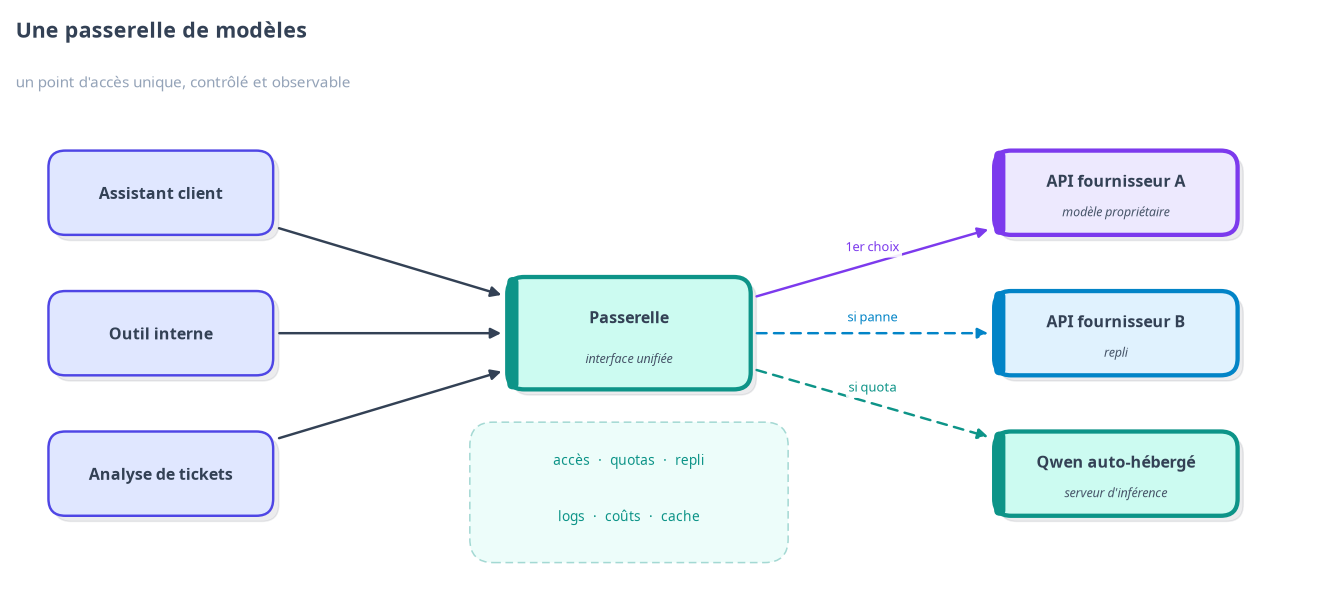

In [10]:
d = Diagram(14, 5.2, title="Une passerelle de modèles", subtitle="un point d'accès unique, contrôlé et observable")
for i, (n, t) in enumerate([("a1", "Assistant client"), ("a2", "Outil interne"), ("a3", "Analyse de tickets")]):
    d.box(n, 1.6, 4.2 - 1.5 * i, t, color=INDIGO, w=2.4)
d.box("gw", 6.6, 2.7, "Passerelle", sub="interface unifiée", color=TEAL, kind="model", w=2.6, h=1.2)
d.group(4.9, 0.25, 8.3, 1.75, None, color=TEAL)
d.note(6.6, 1.35, "accès  ·  quotas  ·  repli", color=TEAL, style="normal", fontsize=9)
d.note(6.6, 0.75, "logs  ·  coûts  ·  cache", color=TEAL, style="normal", fontsize=9)
for i, (n, t, s) in enumerate([("p1", "API fournisseur A", "modèle propriétaire"), ("p2", "API fournisseur B", "repli"),
                               ("p3", "Qwen auto-hébergé", "serveur d'inférence")]):
    d.box(n, 11.8, 4.2 - 1.5 * i, t, sub=s, color=[VIOLET, SKY, TEAL][i], kind="model", w=2.6)
for n in ["a1", "a2", "a3"]:
    d.arrow(n, "gw")
d.arrow("gw", "p1", "1er choix", color=VIOLET)
d.arrow("gw", "p2", "si panne", color=SKY, style="dashed")
d.arrow("gw", "p3", "si quota", color=TEAL, style="dashed")
d.show()

Notre `ModelGateway` implémente ces fonctions en quelques dizaines de lignes. Déclarons
deux fournisseurs : une « API externe » simulée (en réalité Qwen, enveloppé dans un
injecteur de pannes qui renvoie une erreur 503 dans 40 % des cas) et le Qwen
« auto-hébergé » comme repli. Les prix sont des ordres de grandeur en dollars par million
de tokens.

In [11]:
api = A.Provider("api-externe", qwen, price_in=0.5, price_out=1.5, fail_rate=0.4, base_ms=400, ms_per_token=15, seed=3)
local = A.Provider("qwen-local", qwen, price_in=0.05, price_out=0.05, base_ms=250, ms_per_token=25)
gw = A.ModelGateway([api, local], rate_limit=(5, 1.0))
qs = ["Donne un synonyme de rapide.", "Traduis 'merci' en anglais.", "Combien font 12 x 3 ?",
      "Cite une couleur primaire.", "Donne un antonyme de chaud.", "Quelle est la capitale de l'Italie ?"]
for t, q in enumerate(qs):
    r = gw.call([{"role": "user", "content": q}], app="assistant", now=float(t))
logs = pd.DataFrame(gw.logs); logs["cout_$"] = logs["cout_$"].map("{:.1e}".format); logs

,t,app,statut,fournisseur,tentatives,latence_ms,cout_$
0,0.0,assistant,200 ok,qwen-local,2,1075.0,7.5e-07
1,1.0,assistant,200 ok,qwen-local,2,1100.0,7.5e-07
2,2.0,assistant,200 ok,api-externe,1,730.0,3.7e-05
3,3.0,assistant,200 ok,api-externe,1,1435.0,1.1e-04
4,4.0,assistant,200 ok,qwen-local,2,1050.0,7.0e-07
5,5.0,assistant,200 ok,api-externe,1,1375.0,1.0e-04


Quand l'API externe renvoie une erreur, la passerelle bascule sur le modèle local :
l'application ne voit qu'une latence un peu plus forte. Chaque appel est **journalisé**
(fournisseur, tentatives, latence, coût), matière première du monitoring (cours 3).

**Disponibilité avec repli.** Si les fournisseurs tombent en panne indépendamment, avec des
disponibilités $a_1, \dots, a_m$, la requête échoue seulement si tous échouent :
$$A = 1 - \prod_{i=1}^{m} (1 - a_i).$$
Deux fournisseurs à 99 % donnent 99,99 % : on passe de 7 h 18 min d'indisponibilité par
mois à environ 4 minutes. L'hypothèse d'indépendance est optimiste (une panne de
l'hébergeur cloud peut toucher les deux). Vérifions par simulation, avec de faux modèles
instantanés pour aller vite.

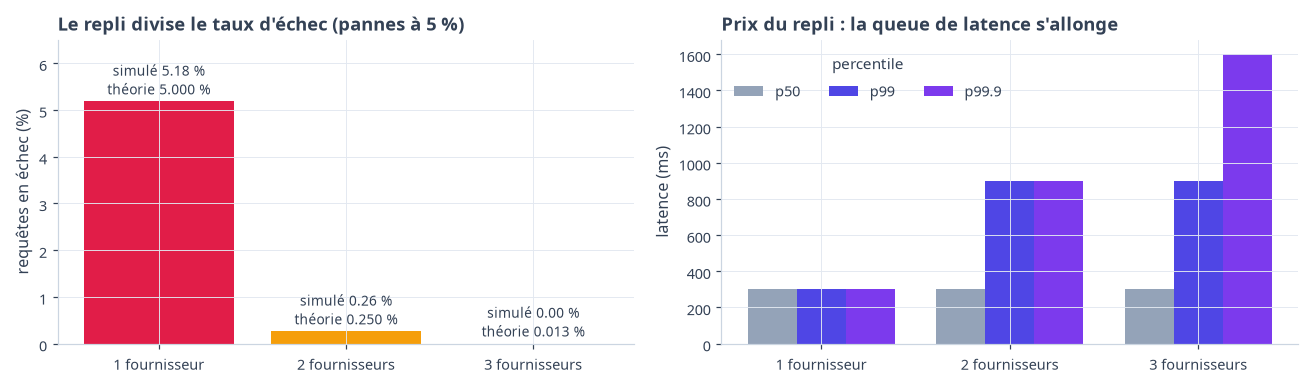

In [12]:
def simulate_availability(fail_rates, n=5000, seed=0):
    provs = [A.Provider(f"p{i}", lambda m: "ok", fail_rate=f, base_ms=300 + 100 * i, ms_per_token=0, seed=seed + i)
             for i, f in enumerate(fail_rates)]
    g = A.ModelGateway(provs)
    res = [g.call("x") for _ in range(n)]
    return np.mean([r.text is not None for r in res]), np.array([r.latency_ms for r in res if r.text])

configs = {"1 fournisseur": [0.05], "2 fournisseurs": [0.05, 0.05], "3 fournisseurs": [0.05, 0.05, 0.05]}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for i, (name, fr) in enumerate(configs.items()):
    av, lat = simulate_availability(fr)
    theo = 1 - np.prod(fr)
    ax[0].bar(i, 100 * (1 - av), color=[ROSE, AMBER, TEAL][i])
    ax[0].text(i, 100 * (1 - av) + 0.15, f"simulé {100 * (1 - av):.2f} %\nthéorie {100 * (1 - theo):.3f} %", ha="center", fontsize=9)
    for j, q in enumerate([50, 99, 99.9]):
        ax[1].bar(i + (j - 1) * 0.26, np.percentile(lat, q), 0.26, color=[GRAY, INDIGO, VIOLET][j],
                  label=f"p{q:g}" if i == 0 else None)
ax[0].set_xticks(range(3), list(configs)); ax[0].set_ylim(0, 6.5)
ax[0].set(ylabel="requêtes en échec (%)", title="Le repli divise le taux d'échec (pannes à 5 %)")
ax[1].set_xticks(range(3), list(configs))
ax[1].set(ylabel="latence (ms)", title="Prix du repli : la queue de latence s'allonge")
ax[1].legend(title="percentile", ncol=3); plt.tight_layout(); plt.show()

Le repli fait chuter le taux d'échec, mais les requêtes rattrapées paient la tentative
ratée et l'attente avant de basculer : la distribution des latences gagne une **queue**.

**Limitation de débit.** La passerelle protège aussi le budget (et les quotas du
fournisseur) avec un **seau à jetons** : un seau de capacité $B$ se remplit à $r$ jetons par
seconde, chaque requête consomme un jeton, et une requête sans jeton reçoit une erreur 429.
Le débit soutenu est $r$ requêtes/s, mais des rafales jusqu'à $B$ requêtes passent.

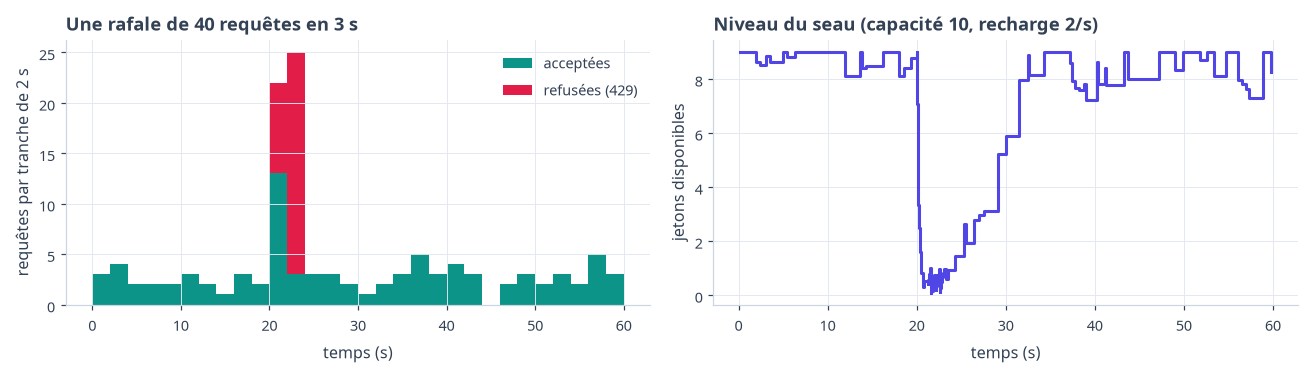

31 requêtes refusées sur 120


In [13]:
bucket = A.TokenBucket(capacity=10, rate=2.0)
t_arr = np.sort(np.concatenate([rng.uniform(0, 60, 80), rng.uniform(20, 23, 40)]))   # trafic + rafale à t = 20 s
ok, level = [], []
for t in t_arr:
    ok.append(bucket.allow(t)); level.append(bucket.tokens)
ok = np.array(ok)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
bins = np.arange(0, 61, 2)
ax[0].hist([t_arr[ok], t_arr[~ok]], bins=bins, stacked=True, color=[TEAL, ROSE], label=["acceptées", "refusées (429)"])
ax[0].set(xlabel="temps (s)", ylabel="requêtes par tranche de 2 s", title="Une rafale de 40 requêtes en 3 s")
ax[0].legend()
ax[1].step(t_arr, level, color=INDIGO, where="post")
ax[1].set(xlabel="temps (s)", ylabel="jetons disponibles", title="Niveau du seau (capacité 10, recharge 2/s)")
plt.tight_layout(); plt.show()
print(f"{(~ok).sum()} requêtes refusées sur {len(ok)}")

Enfin, le **contrôle d'accès** : on déclare quels modèles chaque application peut utiliser.

In [14]:
gw_acl = A.ModelGateway([api, local], access={"stagiaire": {"qwen-local"}, "assistant": {"api-externe", "qwen-local"}})
for app_name in ["stagiaire", "inconnu"]:
    r = gw_acl.call("Bonjour", app=app_name)
    print(f"{app_name:10s} -> statut {r.status}, fournisseur {r.provider}")

stagiaire  -> statut 200 ok, fournisseur qwen-local
inconnu    -> statut 403 accès refusé, fournisseur None


> **À retenir.** La passerelle unifie l'accès aux modèles, garde les clés, plafonne les
> coûts, journalise tout et rend l'application résiliente par le repli :
> $A = 1 - \prod (1 - a_i)$, au prix d'une queue de latence.

## 3. Étape 4a : le cache exact (section *Exact caching*)

Les caches réduisent la latence et le coût. Le chapitre 9 a traité les caches
d'**inférence** (cache KV, cache de prompt) ; ici il s'agit des caches **système**. Avec
un **cache exact**, on ne réutilise une réponse que si la requête est **identique** (après
normalisation : minuscules, ponctuation). C'est utile pour les requêtes répétées (résumés de
fiches produits, recherche vectorielle d'une même requête) et pour les étapes coûteuses
(chaîne de raisonnement, SQL, recherche web).

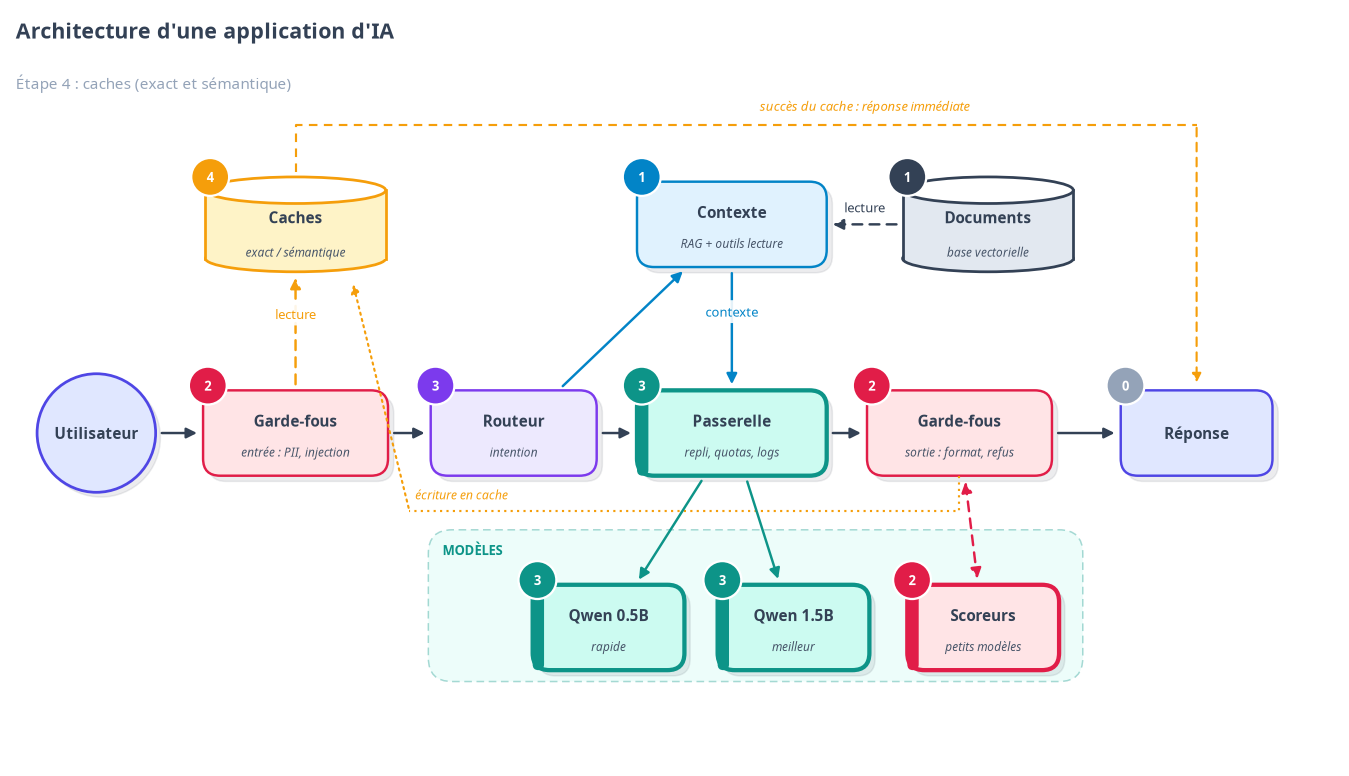

In [15]:
A.architecture_diagram(4);

**Le cache marche-t-il ?** Tout dépend de la distribution des requêtes. Le trafic réel
suit souvent une **loi de Zipf** : la $i$-ème requête la plus fréquente a une probabilité
$p_i \propto 1/i^s$. Si le cache contenait en permanence les $C$ requêtes les plus
fréquentes parmi $N$, son taux de succès serait
$$h(C) = \frac{\sum_{i=1}^{C} i^{-s}}{\sum_{i=1}^{N} i^{-s}} = \frac{H_{C,s}}{H_{N,s}},$$
où $H_{n,s}$ est le nombre harmonique généralisé. Pour $s = 1$, $H_{n,1} \approx \ln n + 0{,}577$ :
avec $N = 10\,000$ requêtes distinctes, un cache de 100 entrées (1 %) capte déjà environ la
moitié du trafic. Les politiques réelles (LRU, FIFO) ne connaissent pas les fréquences :
comparons-les à cette borne.

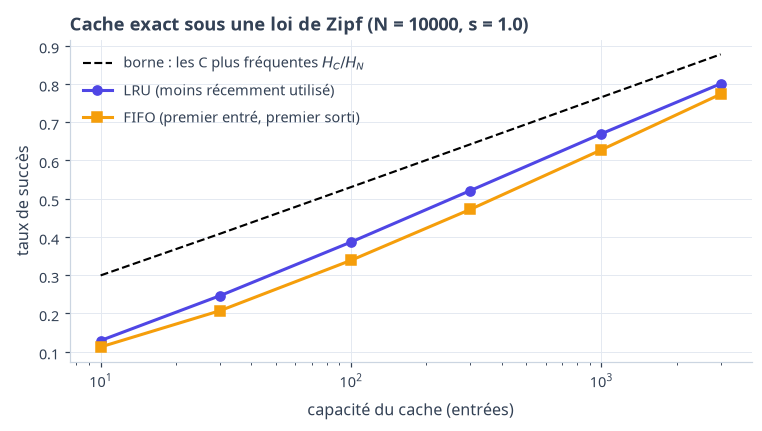

In [16]:
N, s_zipf, n_req = 10_000, 1.0, 40_000
p = 1 / np.arange(1, N + 1) ** s_zipf; p /= p.sum()
stream = rng.choice(N, size=n_req, p=p)
caps = [10, 30, 100, 300, 1000, 3000]
res = {"LRU": [], "FIFO": []}
for cap in caps:
    for pol in res:
        c = A.ExactCache(capacity=cap, policy=pol.lower(), normalize_key=False)
        for q in stream:
            if c.get(str(q)) is None:
                c.put(str(q), 1)
        res[pol].append(c.hit_rate)
H = np.cumsum(1 / np.arange(1, N + 1) ** s_zipf)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(caps, [H[c - 1] / H[-1] for c in caps], "k--", lw=1.4, label="borne : les C plus fréquentes $H_{C}/H_{N}$")
ax.plot(caps, res["LRU"], "o-", color=INDIGO, label="LRU (moins récemment utilisé)")
ax.plot(caps, res["FIFO"], "s-", color=AMBER, label="FIFO (premier entré, premier sorti)")
ax.set(xscale="log", xlabel="capacité du cache (entrées)", ylabel="taux de succès",
       title=f"Cache exact sous une loi de Zipf (N = {N}, s = {s_zipf})")
ax.legend(); plt.show()

LRU fait mieux que FIFO car il garde ce qui sert souvent, mais reste sous la borne
(il gaspille de la place pour des requêtes rares récentes) ; LFU (moins fréquemment
utilisé) s'en approcherait sur un trafic stable. Les courbes sont presque des droites en
échelle logarithmique : chaque **décuplement** de la capacité ajoute à peu près le même
nombre de points de taux de succès (environ 0,25 ici). C'est un rendement décroissant :
passer de 100 à 1 000 entrées rapporte autant que passer de 10 à 100.

**Que ne pas mettre en cache ?** Les requêtes **personnelles** (« où en est ma
commande ? ») et **datées** (« quel temps fait-il ? »). L'encadré du livre raconte une fuite
typique : une question d'apparence générique (« quelle est la politique de retour ? ») dont
la réponse dépend du statut de l'utilisateur X est mise en cache, puis servie à
l'utilisateur Y. Beaucoup d'équipes entraînent un classifieur « à mettre en cache ou non » ;
notre `is_cacheable` est une version à base de règles (exercice 10.7).

In [17]:
exemples = ["Quels moyens de paiement acceptez-vous ?", "Où en est ma commande 1042 ?",
            "Quel temps fait-il aujourd'hui à Lyon ?", "Quelle est la durée de garantie d'un téléviseur ?",
            "Quelle est la politique de retour pour les membres premium ?"]
pd.DataFrame({"requête": exemples, "mise en cache autorisée": [A.is_cacheable(e) for e in exemples]})

,requête,mise en cache autorisée
0,Quels moyens de paiement acceptez-vous ?,True
1,Où en est ma commande 1042 ?,False
2,Quel temps fait-il aujourd'hui à Lyon ?,False
3,Quelle est la durée de garantie d'un téléviseur ?,True
4,Quelle est la politique de retour pour les membres premium ?,True


La dernière ligne montre la limite des règles : la requête paraît générique, mais si la
réponse est construite à partir du profil de l'utilisateur, elle ne doit pas être
partagée. La solution robuste est d'inclure dans la clé de cache tout ce dont dépend la
réponse (par exemple le segment de l'utilisateur).

> **À retenir.** Le taux de succès d'un cache exact dépend de la concentration du trafic
> (Zipf) et de la politique d'éviction ; ne mettez jamais en cache une réponse qui dépend
> de l'utilisateur sans l'inclure dans la clé.